In [1]:
# load env variables from .env file
from dotenv import load_dotenv
load_dotenv()
import os

In [5]:
# Creating the API CLient
from anthropic import Anthropic

client = Anthropic(
    base_url=os.getenv("ANTHROPIC_BASE_URL"),
    api_key=os.getenv("ANTHROPIC_AUTH_TOKEN"),
    default_headers={
        "anthropic-beta": "code-execution-2025-08-25, files-api-2025-04-14"
    }
)

model = os.getenv("ANTHROPIC_MODEL")


In [7]:
# Helper functions
from anthropic.types import Message


def add_user_message(messages, message):
    user_message = {
        "role": "user",
        "content": message.content if isinstance(message, Message) else message,
    }
    messages.append(user_message)


def add_assistant_message(messages, message):
    assistant_message = {
        "role": "assistant",
        "content": message.content if isinstance(message, Message) else message,
    }
    messages.append(assistant_message)


def chat(
    messages,
    system=None,
    temperature=1.0,
    stop_sequences=[],
    tools=None,
    thinking=False,
    thinking_budget=2000,
):
    params = {
        "model": model,
        "max_tokens": 10000,
        "messages": messages,
        "temperature": temperature,
        "stop_sequences": stop_sequences,
    }

    if thinking:
        params["thinking"] = {
            "type": "enabled",
            "budget_tokens": thinking_budget,
        }

    if tools:
        params["tools"] = tools

    if system:
        params["system"] = system

    message = client.messages.create(**params)
    return message


def text_from_message(message):
    return "\n".join([block.text for block in message.content if block.type == "text"])


def upload(file_path):
    path = Path(file_path)
    extension = path.suffix.lower()

    mime_type_map = {
        ".pdf": "application/pdf",
        ".txt": "text/plain",
        ".md": "text/plain",
        ".py": "text/plain",
        ".js": "text/plain",
        ".html": "text/plain",
        ".css": "text/plain",
        ".csv": "text/csv",
        ".json": "application/json",
        ".xml": "application/xml",
        ".xlsx": "application/vnd.openxmlformats-officedocument.spreadsheetml.sheet",
        ".xls": "application/vnd.ms-excel",
        ".jpeg": "image/jpeg",
        ".jpg": "image/jpeg",
        ".png": "image/png",
        ".gif": "image/gif",
        ".webp": "image/webp",
    }

    mime_type = mime_type_map.get(extension)

    if not mime_type:
        raise ValueError(f"Unknown mimetype for extension: {extension}")
    filename = path.name

    with open(file_path, "rb") as file:
        return client.beta.files.upload(file=(filename, file, mime_type))


def list_files():
    return client.beta.files.list()


def delete_file(id):
    return client.beta.files.delete(id)


def download_file(id, filename=None):
    file_content = client.beta.files.download(id)

    if not filename:
        file_metadata = get_metadata(id)
        file_content.write_to_file(file_metadata.filename)
    else:
        file_content.write_to_file(filename)


def get_metadata(id):
    return client.beta.files.retrieve_metadata(id)

In [9]:
import pandas as pd

df = pd.read_csv("streaming.csv")

print(df.head())
print(df.info())

       UserID SubscriptionTier  TotalViewingHoursLastMonth     TopGenre  \
0  USER_00001            Basic                        47.9       Comedy   
1  USER_00002          Premium                        41.4        Drama   
2  USER_00003         Standard                        33.6       Action   
3  USER_00004         Standard                       115.6       Action   
4  USER_00005            Basic                        93.8  Documentary   

   BingeWatchingSessionsLastMonth  NumberOfUniqueTitlesWatchedLastMonth  \
0                               5                                    15   
1                               5                                     9   
2                               1                                     7   
3                              12                                    33   
4                               9                                    27   

   AverageSessionDurationMinutes  CustomerServiceInteractionsLastYear  \
0                        

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def analyze_churn(file_path, churn_column="Churn"):

    # 1. Load dataset
    df = pd.read_csv(file_path)

    print("=" * 60)
    print("CUSTOMER CHURN ANALYSIS")
    print("=" * 60)

    # 2. Basic dataset information
    print("\nDataset Shape:", df.shape)
    print("\nMissing Values:\n", df.isnull().sum())
    print("\nDataset Preview:\n", df.head())

    if churn_column not in df.columns:
        raise ValueError(
            f"'{churn_column}' not found. Available columns: {df.columns.tolist()}"
        )

    # 3. Overall churn distribution
    churn_counts = df[churn_column].value_counts()

    churn_rate = (
        df[churn_column]
        .value_counts(normalize=True) * 100
    )

    print("\nChurn Distribution:\n", churn_counts)
    print("\nChurn Percentage:\n", churn_rate)

    # 4. Identify numerical and categorical columns
    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    numerical_columns = [
        col for col in numerical_columns
        if col != churn_column
    ]

    categorical_columns = [
        col for col in categorical_columns
        if col != churn_column
    ]

    # 5. Analyze numerical features
    numerical_analysis = {}

    for col in numerical_columns:

        numerical_analysis[col] = (
            df.groupby(churn_column)[col]
            .mean()
            .to_dict()
        )

    # 6. Analyze categorical features
    categorical_analysis = {}

    for col in categorical_columns:

        categorical_analysis[col] = (
            pd.crosstab(
                df[col],
                df[churn_column],
                normalize="index"
            ) * 100
        ).round(2).to_dict()

    # 7. Generate churn visualization
    plt.figure(figsize=(16, 12))

    # Churn distribution
    plt.subplot(2, 2, 1)

    sns.countplot(
        data=df,
        x=churn_column
    )

    plt.title("Overall Churn Distribution")

    # Numerical feature comparison
    if numerical_columns:

        plt.subplot(2, 2, 2)

        selected_feature = numerical_columns[0]

        sns.boxplot(
            data=df,
            x=churn_column,
            y=selected_feature
        )

        plt.title(f"{selected_feature} vs Churn")

    # Categorical feature comparison
    if categorical_columns:

        plt.subplot(2, 2, 3)

        selected_feature = categorical_columns[0]

        churn_percentage = pd.crosstab(
            df[selected_feature],
            df[churn_column],
            normalize="index"
        ) * 100

        if len(churn_percentage.columns) >= 2:

            sns.heatmap(
                churn_percentage,
                annot=True,
                fmt=".1f",
                cmap="Reds"
            )

            plt.title(f"{selected_feature} vs Churn (%)")

    # Correlation analysis
    if len(numerical_columns) > 1:

        plt.subplot(2, 2, 4)

        correlation = df[numerical_columns].corr()

        sns.heatmap(
            correlation,
            cmap="coolwarm",
            center=0
        )

        plt.title("Numerical Feature Correlation")

    plt.tight_layout()

    plt.savefig(
        "churn_analysis.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # 8. Prepare analysis context
    summary = df.describe(include="all").to_string()

    analysis_context = f"""
    Dataset Shape:
    {df.shape}

    Churn Distribution:
    {churn_counts.to_string()}

    Churn Percentage:
    {churn_rate.to_string()}

    Numerical Feature Analysis:
    {numerical_analysis}

    Categorical Feature Analysis:
    {categorical_analysis}

    Dataset Summary:
    {summary}
    """

    # 9. Send analysis to Qwen
    messages = []

    add_user_message(
        messages,
        f"""
        You are a senior data analyst specializing in customer analytics.

        Analyze the following customer churn dataset.

        Identify:
        1. Major drivers of customer churn.
        2. Customer segments with the highest churn.
        3. Important numerical and categorical patterns.
        4. Relationships between customer attributes and churn.
        5. Potential business reasons behind churn.
        6. Actionable strategies to reduce churn.

        Distinguish statistical associations from causal explanations.
        Use actual numerical findings rather than assumptions.

        Dataset Analysis:
        {analysis_context}

        Provide a detailed, structured analytical report.
        """
    )

    response = chat(messages, temperature=0.3)

    # 10. Print final report
    report = text_from_message(response)

    print("\n" + "=" * 60)
    print("AI-GENERATED CHURN ANALYSIS REPORT")
    print("=" * 60)

    print(report)

    return {
        "data": df,
        "churn_distribution": churn_counts,
        "numerical_analysis": numerical_analysis,
        "categorical_analysis": categorical_analysis,
        "report": report,
        "plot": "churn_analysis.png"
    }

CUSTOMER CHURN ANALYSIS

Dataset Shape: (500, 10)

Missing Values:
 UserID                                  0
SubscriptionTier                        0
TotalViewingHoursLastMonth              0
TopGenre                                0
BingeWatchingSessionsLastMonth          0
NumberOfUniqueTitlesWatchedLastMonth    0
AverageSessionDurationMinutes           0
CustomerServiceInteractionsLastYear     0
MonthlyCost                             0
Churned                                 0
dtype: int64

Dataset Preview:
        UserID SubscriptionTier  TotalViewingHoursLastMonth     TopGenre  \
0  USER_00001            Basic                        47.9       Comedy   
1  USER_00002          Premium                        41.4        Drama   
2  USER_00003         Standard                        33.6       Action   
3  USER_00004         Standard                       115.6       Action   
4  USER_00005            Basic                        93.8  Documentary   

   BingeWatchingSessionsLastM

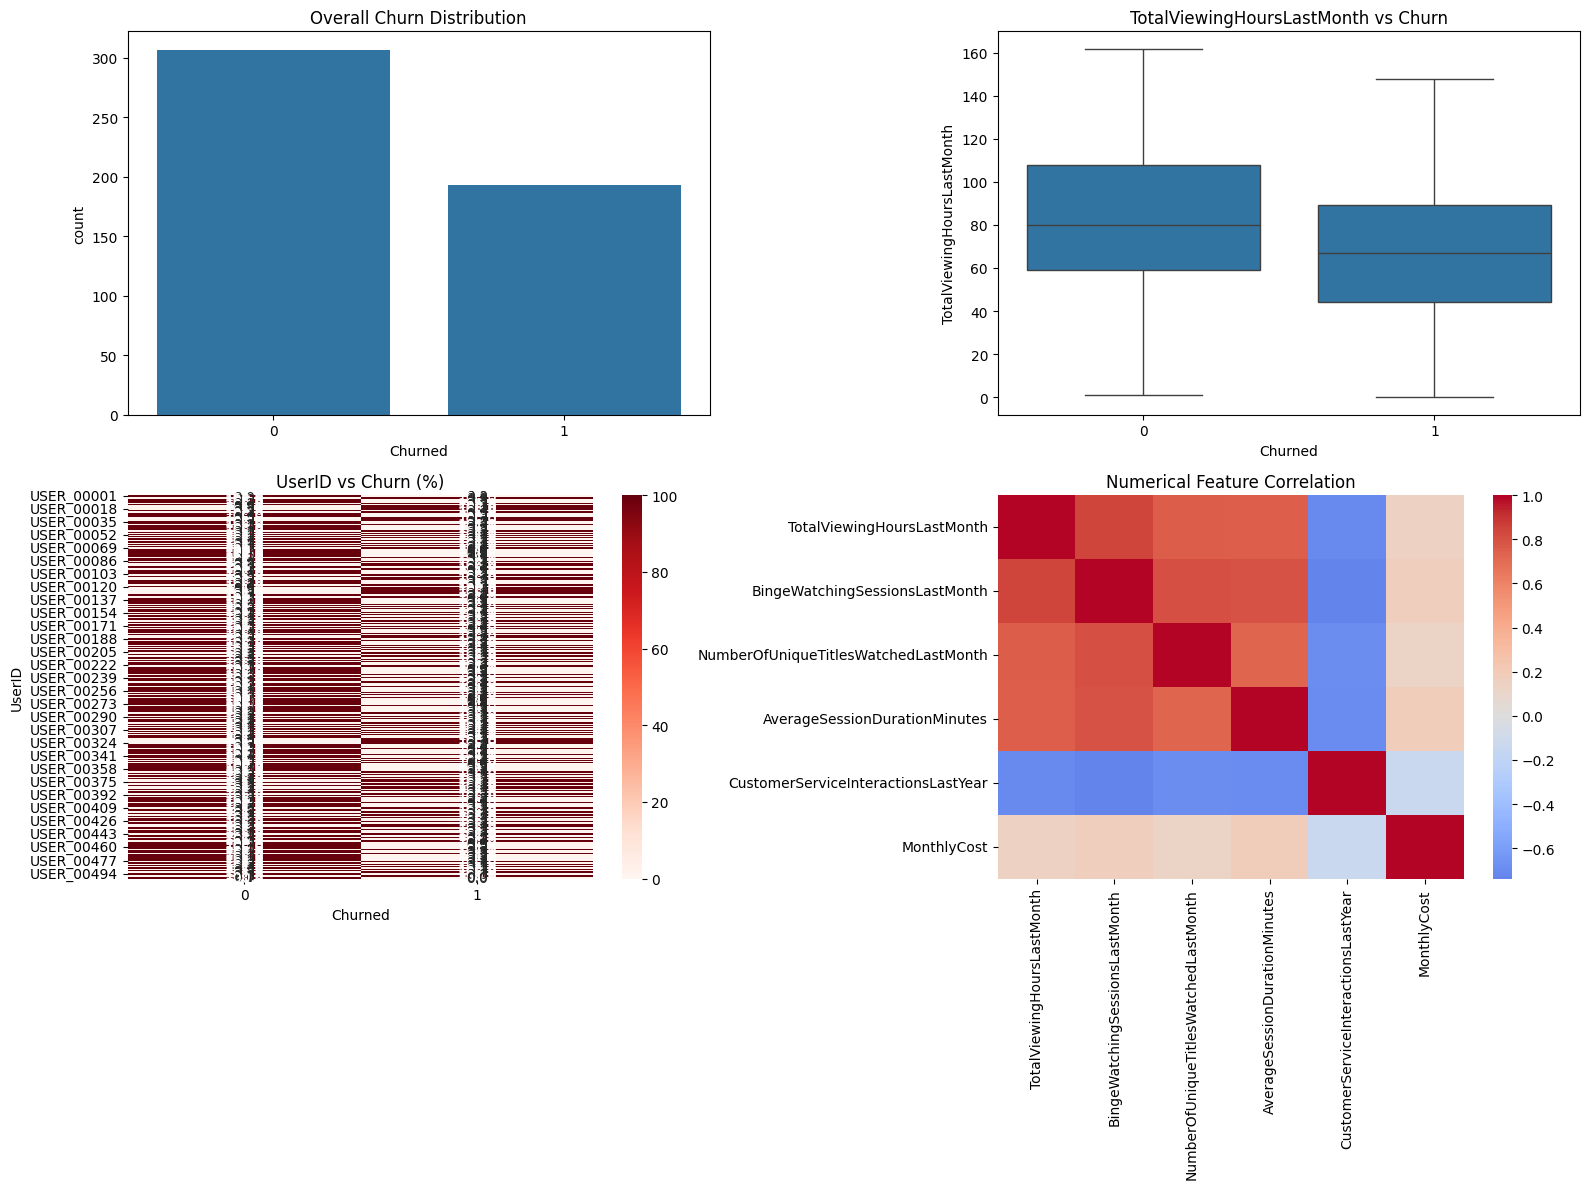


AI-GENERATED CHURN ANALYSIS REPORT
### Analytical Report

#### Dataset Overview
The dataset contains information on subscribers of a streaming service. The dataset is structured with 500 unique users, each with multiple attributes related to their viewing habits, subscription tiers, and customer service interactions. The attributes include Total Viewing Hours, Top Genre, Binge Watching Sessions, Unique Titles Watched, Average Session Duration, Customer Service Interactions, Monthly Cost, and Churn Status.

#### Detailed Analysis

##### 1. **User Demographics and Subscription Tiers**
   - **Subscription Tiers**: The dataset shows that 56.52% of users are on the Basic tier, 75.9% are on the Premium tier, and 60.48% are on the Standard tier. The distribution of users across tiers is relatively even, with a slight preference for the Standard tier.
   - **Churn Status**: Among the 500 users, 100 users have churned, indicating a churn rate of 20% (100/500). This churn rate is relatively hig

In [18]:
results = analyze_churn(
    file_path="streaming.csv",
    churn_column="Churned"
)

In [19]:
# AI-generated report
print(results["report"])

# Churn distribution
print(results["churn_distribution"])

# Numerical analysis
print(results["numerical_analysis"])

# Categorical analysis
print(results["categorical_analysis"])

### Analytical Report

#### Dataset Overview
The dataset contains information on subscribers of a streaming service. The dataset is structured with 500 unique users, each with multiple attributes related to their viewing habits, subscription tiers, and customer service interactions. The attributes include Total Viewing Hours, Top Genre, Binge Watching Sessions, Unique Titles Watched, Average Session Duration, Customer Service Interactions, Monthly Cost, and Churn Status.

#### Detailed Analysis

##### 1. **User Demographics and Subscription Tiers**
   - **Subscription Tiers**: The dataset shows that 56.52% of users are on the Basic tier, 75.9% are on the Premium tier, and 60.48% are on the Standard tier. The distribution of users across tiers is relatively even, with a slight preference for the Standard tier.
   - **Churn Status**: Among the 500 users, 100 users have churned, indicating a churn rate of 20% (100/500). This churn rate is relatively high, suggesting that the service may n